In [1]:
print("Calories Burnt Prediction Project")
print("Starting Machine Learning!")


Calories Burnt Prediction Project
Starting Machine Learning!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
calories = pd.read_csv('/content/calories.csv')
exercise = pd.read_csv('/content/exercise.csv')

print("CALORIES DATASET")
display(calories.head())

print("EXERCISE DATASET")
display(exercise.head())

print("Calories shape:", calories.shape)
print("Exercise shape:", exercise.shape)

CALORIES DATASET


,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0


EXERCISE DATASET


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8


Calories shape: (15000, 2)
Exercise shape: (15000, 8)


In [4]:
data = pd.merge(exercise, calories, on='User_ID')

print("Merged dataset:")
display(data.head())

print("Dataset shape:", data.shape)
print(data.info())

Merged dataset:


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


Dataset shape: (15000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  float64
dtypes: float64(6), int64(2), object(1)
memory usage: 1.0+ MB
None


In [5]:
print("Missing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nStatistical summary:")
display(data.describe())

Missing values:
User_ID       0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64

Duplicate rows: 0

Statistical summary:


,User_ID,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,1.497736e+07,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453,89.539533
std,2.872851e+06,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230,62.456978
min,1.000116e+07,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,1.247419e+07,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000
50%,1.499728e+07,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000,79.000000
75%,1.744928e+07,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,1.999965e+07,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000


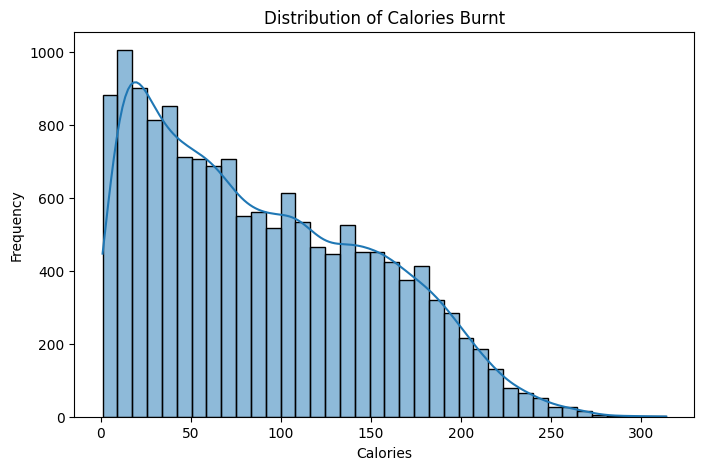

In [6]:
plt.figure(figsize=(8,5))
sns.histplot(data['Calories'], kde=True)
plt.title('Distribution of Calories Burnt')
plt.xlabel('Calories')
plt.ylabel('Frequency')
plt.show()

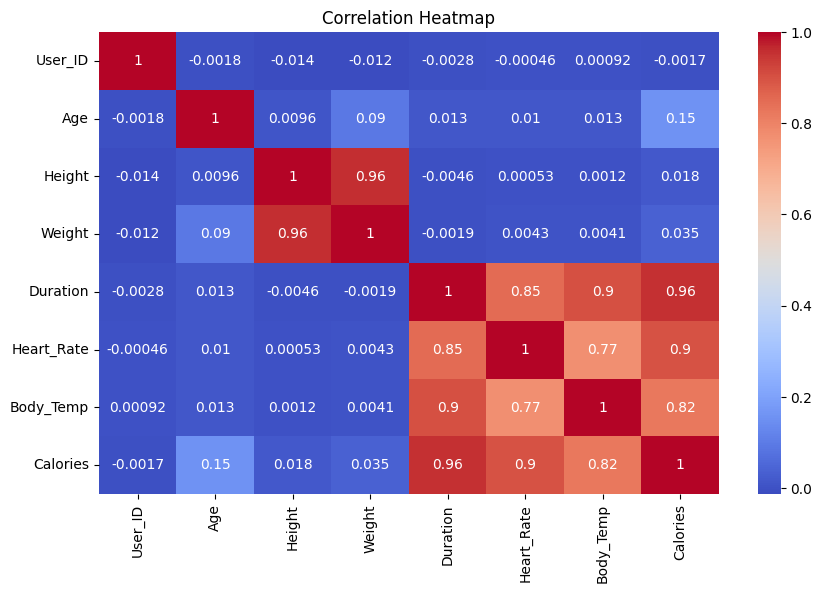

In [7]:
plt.figure(figsize=(10,6))

sns.heatmap(
    data.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

In [8]:
data['Gender'] = data['Gender'].map({
    'male': 0,
    'female': 1
})

data = data.drop('User_ID', axis=1)

X = data.drop('Calories', axis=1)
y = data['Calories']

print("Input features:")
display(X.head())

print("Target:")
display(y.head())

Input features:


,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,0,68,190.0,94.0,29.0,105.0,40.8
1,1,20,166.0,60.0,14.0,94.0,40.3
2,0,69,179.0,79.0,5.0,88.0,38.7
3,1,34,179.0,71.0,13.0,100.0,40.5
4,1,27,154.0,58.0,10.0,81.0,39.8


Target:


,Calories
0,231.0
1,66.0
2,26.0
3,71.0
4,35.0


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 12000
Testing samples: 3000


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    "Lasso": Lasso(),
    "Ridge": Ridge()
}

results = {}

for name, model in models.items():

    if name == "Random Forest":
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
    else:
        model.fit(X_train_scaled, y_train)
        predictions = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

    print("\nModel:", name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


Model: Linear Regression
MAE: 8.441513553849706
RMSE: 11.48894014915288
R2 Score: 0.9672937151257295

Model: Random Forest
MAE: 1.7151600000000002
RMSE: 2.670973517901915
R2 Score: 0.9982322923338827

Model: Lasso
MAE: 9.144387298336845
RMSE: 12.56192545181704
R2 Score: 0.9608993745233644

Model: Ridge
MAE: 8.441186197335306
RMSE: 11.489209781378891
R2 Score: 0.9672921799498538


,MAE,RMSE,R2 Score
Random Forest,1.715160,2.670974,0.998232
Ridge,8.441186,11.489210,0.967292
Linear Regression,8.441514,11.488940,0.967294
Lasso,9.144387,12.561925,0.960899


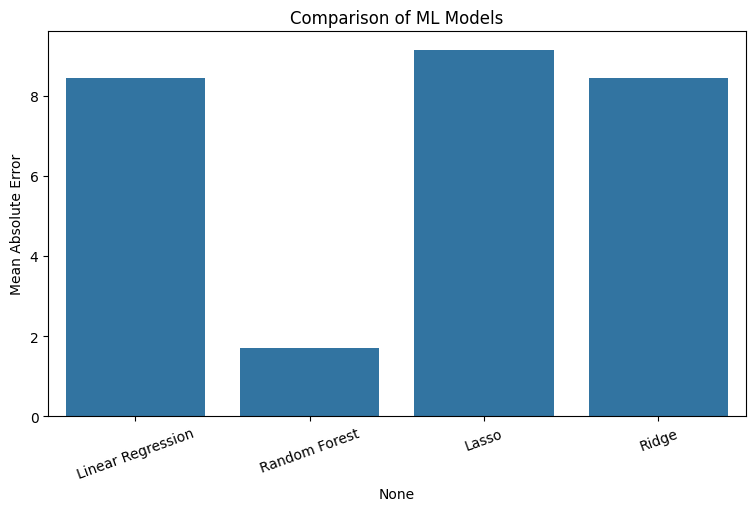

In [12]:
results_df = pd.DataFrame(results).T

display(results_df.sort_values(by='MAE'))

plt.figure(figsize=(9,5))
sns.barplot(
    x=results_df.index,
    y=results_df['MAE']
)

plt.title('Comparison of ML Models')
plt.ylabel('Mean Absolute Error')
plt.xticks(rotation=20)
plt.show()

In [14]:
best_model_name = results_df['MAE'].idxmin()

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("MAE:", results_df.loc[best_model_name, 'MAE'])
print("R2 Score:", results_df.loc[best_model_name, 'R2 Score'])

Best Model: Random Forest
MAE: 1.7151600000000002
R2 Score: 0.9982322923338827


In [15]:
import joblib

model_package = {
    'model': best_model,
    'scaler': scaler,
    'model_name': best_model_name,
    'scale_required': best_model_name != 'Random Forest',
    'features': list(X.columns)
}

joblib.dump(model_package, 'calories_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [16]:
new_person = pd.DataFrame([{
    'Gender': 1,
    'Age': 21,
    'Height': 165,
    'Weight': 60,
    'Duration': 30,
    'Heart_Rate': 110,
    'Body_Temp': 40.0
}])

prediction = best_model.predict(new_person)

print("Predicted Calories Burnt:", round(prediction[0], 2))

Predicted Calories Burnt: 189.18


In [17]:
from google.colab import files

files.download('calories_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:

%%writefile app.py

import streamlit as st
import pandas as pd
import gzip
import pickle

st.set_page_config(
    page_title="Calories Burnt Predictor",
    page_icon="🔥",
    layout="centered"
)

# Load the compressed machine learning model
with gzip.open("calories_model.pkl.gz", "rb") as f:
    package = pickle.load(f)

model = package['model']

# Application title
st.title("🔥 Calories Burnt Prediction")
st.write("Predict calories burnt during exercise using Machine Learning.")

st.divider()

# User input section
st.subheader("Enter Exercise Details")

gender = st.selectbox("Gender", ["Female", "Male"])
age = st.number_input("Age", 10, 100, 21)
height = st.number_input("Height (cm)", 100, 230, 165)
weight = st.number_input("Weight (kg)", 30, 200, 60)
duration = st.number_input("Exercise Duration (minutes)", 1, 120, 30)
heart_rate = st.number_input("Heart Rate", 50, 200, 110)
body_temp = st.number_input("Body Temperature (°C)", 35.0, 43.0, 40.0)

# Prediction
if st.button("Predict Calories", type="primary"):

    user_data = pd.DataFrame([{
        "Gender": 1 if gender == "Female" else 0,
        "Age": age,
        "Height": height,
        "Weight": weight,
        "Duration": duration,
        "Heart_Rate": heart_rate,
        "Body_Temp": body_temp
    }])

    prediction = model.predict(user_data)[0]

    st.success(f"Predicted Calories Burnt: {prediction:.2f} kcal")


Overwriting app.py


In [19]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.6.1


In [22]:
import gzip
import shutil

with open('calories_model.pkl', 'rb') as original:
    with gzip.open('calories_model.pkl.gz', 'wb') as compressed:
        shutil.copyfileobj(original, compressed)

import os

print("Original size:", os.path.getsize('calories_model.pkl') / 1024, "KB")
print("Compressed size:", os.path.getsize('calories_model.pkl.gz') / 1024, "KB")

Original size: 81335.18359375 KB
Compressed size: 11812.03125 KB


In [23]:
from google.colab import files

files.download('calories_model.pkl.gz')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
%%writefile requirements.txt

streamlit
pandas
scikit-learn
joblib

Writing requirements.txt


In [27]:
from google.colab import files

files.download('app.py')
files.download('requirements.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>